# SokoRadar 03: time-series models (trend, stationarity, ARIMA family, forecasting)


| Section | Step | Question it answers |
|---|---|---|
| 1 | Trend and seasonality | What is the long-run direction, and is there a yearly cycle? |
| 2 | Stationarity (ADF, KPSS) | Do the mean and spread stay stable over time? |
| 3 | ACF and PACF | Do past values or past errors help predict the next value? |
| 4 | Preprocessing | Which transforms (log, differencing, seasonal differencing) are needed? |
| 5 | Model zoo | White noise, random walk, AR, MA, ARMA, ARIMA, SARIMA |
| 6 | Walk-forward accuracy | MAE and RMSE against naive, at 1, 2 and 3 months |
| 7 | AIC, BIC and residuals | Which model is the best trade-off, and is anything left over? |
| 8 | **[EST] vs [REAL]** | Do estimated national months change the answer? |
| 9 | Held-out test, 2025-01 to 2026-09 | Does it work on real county markets? |
| 10 | Forecasting and automation | A monthly refresh, intervals, alerts and monitoring |



In [1]:
import json, time, warnings, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.simplefilter('ignore')          # statsmodels re-enables its own warnings on import; switch them off again
BLUE, ORANGE, GREEN, GREY = '#2a78d8', '#e8683a', '#5aa86b', '#9a9a95'

# ---- same loader as notebooks 01 and 02 ----
XNAME = 'SokoRadar_County_2006_2024.xlsx'
here = Path.cwd()
ROOT = next((p for p in [here, *here.parents] if (p / 'output' / XNAME).exists()), None)
if ROOT is not None:                                   # repo layout
    IN = ROOT / 'output' / 'modelling' / 'handoff'
else:                                                  # flat folder, e.g. CAPSTONE2
    ROOT = next((p for p in [here, *here.parents] if (p / XNAME).exists()), None)
    assert ROOT is not None, f'Could not find {XNAME} in {here} or any parent folder.'
    IN = ROOT / 'handoff'
assert (IN / 'meta.json').exists(), f'Handoff not found in {IN}. Run 01_eda_review.ipynb first.'
FIG = IN.parent / 'figures_ts' if IN.parent.name == 'modelling' else ROOT / 'figures_ts'
FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.savefig(FIG / name, dpi=150, bbox_inches='tight')

meta = json.load(open(IN/'meta.json')); CORE, TRAIN, TEST = meta['CORE'], meta['TRAIN'], meta['TEST']
def load_ts(f):
    d = pd.read_csv(IN/f, index_col=0); d.index = pd.PeriodIndex(d.index, freq='M'); return d
P = load_ts('national_prices.csv'); REAL = load_ts('national_real_flag.csv').astype(bool)
led = pd.read_csv(IN/'real_ledger.csv'); led['month'] = pd.PeriodIndex(led['month'], freq='M')

# Modelling window: from the start of training to the LAST month in which any core national price is real.
LAST_REAL = REAL[CORE].any(axis=1)[lambda s: s].index.max()
WIN = (pd.Period(TRAIN[0]), LAST_REAL)
Y = np.log(P.loc[WIN[0]:WIN[1], CORE])                  # log prices: the series we model
print('Core series:', CORE)
print('Modelling window:', WIN[0], 'to', WIN[1], '=', len(Y), 'months | real share in window:', round(float(REAL.loc[WIN[0]:WIN[1], CORE].values.mean()), 3))
print('Months after the window (', WIN[1] + 1, 'to', TRAIN[1], ') are estimated at national level and are used only in the [EST] check (section 8).')

Core series: ['Dry Maize', 'Sorghum', 'Beans Rosecoco', 'Red Irish Potatoes']
Modelling window: 2006-01 to 2022-02 = 194 months | real share in window: 0.966
Months after the window ( 2022-03 to 2024-12 ) are estimated at national level and are used only in the [EST] check (section 8).


## 1. Trend and seasonality
- **Trend** is the slow, long-run movement of the price (up or down over years).
- **Seasonality** is a pattern that repeats every year (for example dearer before harvest).
- We split each series with **STL decomposition** into trend + seasonal + remainder. Two strength scores run from 0 (none) to 1 (everything): *trend strength* and *seasonal strength*. A series with seasonal strength near 0 has no useful yearly cycle even if a peak month can be named.

,drift %/yr,trend strength,seasonal strength,peak month,trough month,seasonal range % (peak vs trough)
series,,,,,,
Dry Maize,4.93,0.75,0.02,7,3,16.35
Sorghum,7.00,0.95,0.06,10,9,8.72
Beans Rosecoco,4.71,0.92,0.31,5,7,20.07
Red Irish Potatoes,5.84,0.71,0.18,5,8,37.58


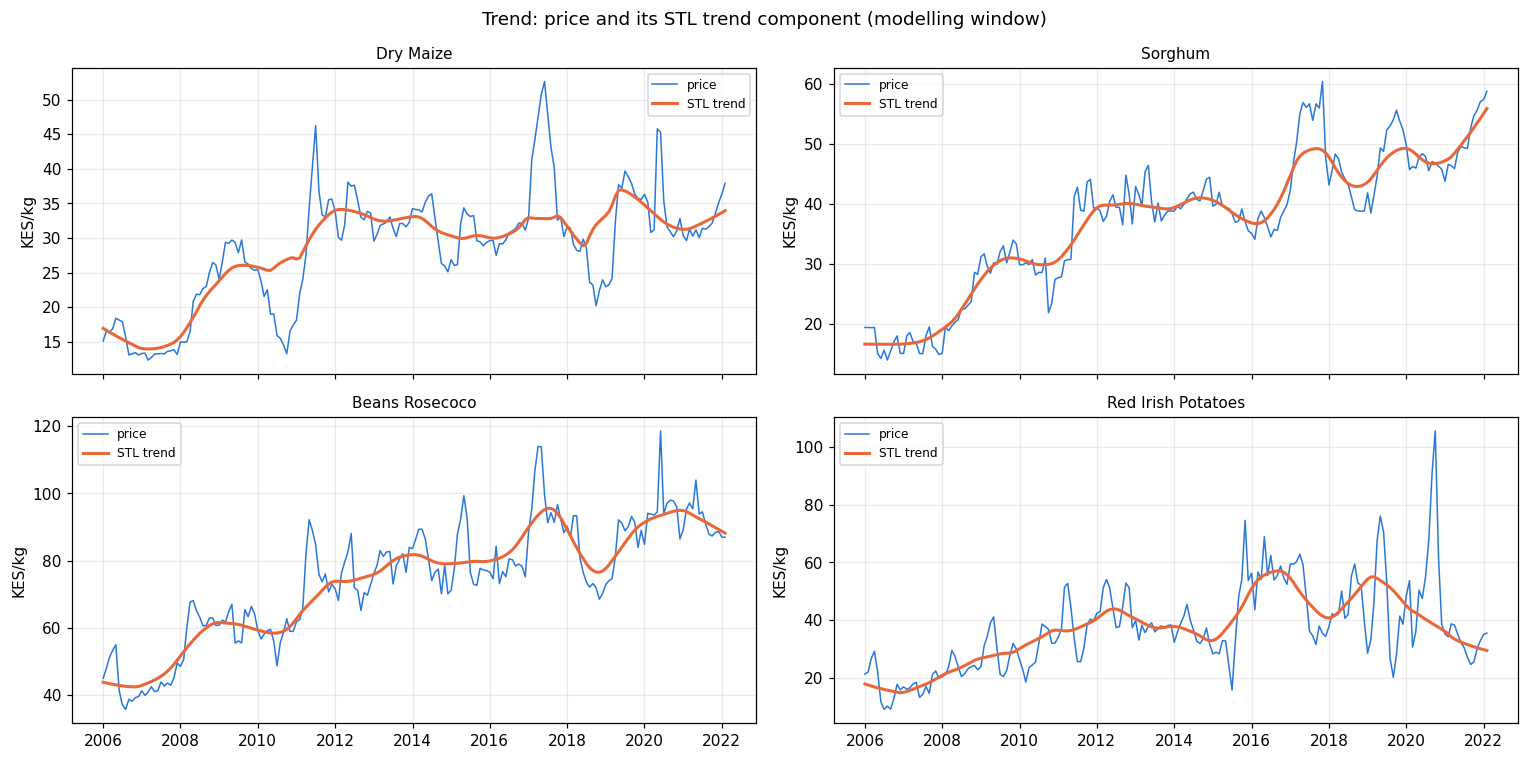

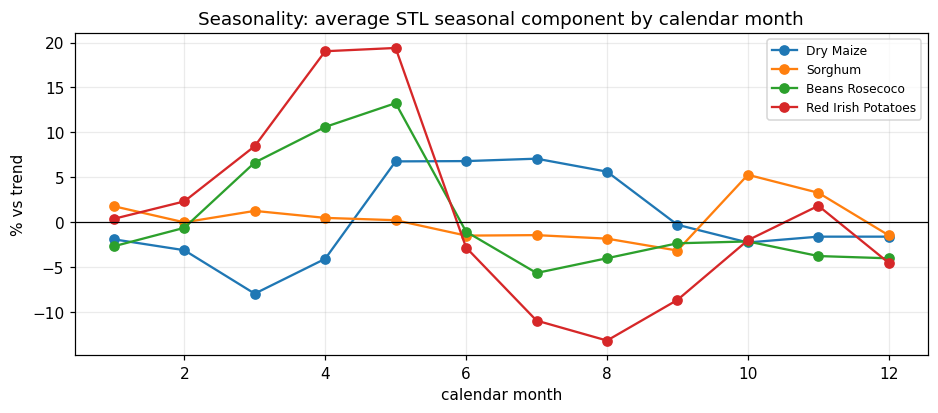

In [2]:
# 1a. Trend and seasonal strength from an STL decomposition (period 12, robust to outliers)
def to_ts(y):
    s = pd.Series(y.values, index=y.index.to_timestamp(how='start')); return s.asfreq('MS')
t_years = np.arange(len(Y)) / 12
rows, STLR = [], {}
for c in CORE:
    stl = STL(to_ts(Y[c]), period=12, robust=True).fit(); STLR[c] = stl
    Ft = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())          # Hyndman trend strength, 0..1
    Fs = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())       # seasonal strength, 0..1
    prof = stl.seasonal.groupby(stl.seasonal.index.month).mean()
    rows.append({'series': c, 'drift %/yr': 100*(np.exp(np.polyfit(t_years, Y[c].values, 1)[0]) - 1),
                 'trend strength': Ft, 'seasonal strength': Fs,
                 'peak month': int(prof.idxmax()), 'trough month': int(prof.idxmin()),
                 'seasonal range % (peak vs trough)': 100*(np.exp(prof.max() - prof.min()) - 1)})
CH = pd.DataFrame(rows).set_index('series'); display(CH.round(2))

fig, axs = plt.subplots(2, 2, figsize=(14, 7), sharex=True); axs = axs.ravel()
for ax, c in zip(axs, CORE):
    ax.plot(Y.index.to_timestamp(), np.exp(Y[c]), color=BLUE, lw=1, label='price')
    ax.plot(STLR[c].trend.index, np.exp(STLR[c].trend), color=ORANGE, lw=2, label='STL trend')
    ax.set_title(c, fontsize=10); ax.set_ylabel('KES/kg'); ax.legend(fontsize=8)
fig.suptitle('Trend: price and its STL trend component (modelling window)'); plt.tight_layout(); save('t01_trend.png'); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
for c in CORE:
    prof = STLR[c].seasonal.groupby(STLR[c].seasonal.index.month).mean(); ax.plot(prof.index, 100*np.expm1(prof.values), marker='o', label=c)
ax.axhline(0, c='k', lw=.8); ax.set_xlabel('calendar month'); ax.set_ylabel('% vs trend'); ax.legend(fontsize=8)
ax.set_title('Seasonality: average STL seasonal component by calendar month'); save('t02_seasonal_profile.png'); plt.show()

**What it shows:** (1) each core price with its STL trend line, (2) the average seasonal shape by calendar month.

**Insight:**
- All four series drift upward: about **4.7 to 7.0% a year** in shillings (sorghum fastest at 7.0%, beans slowest at 4.7%). Trend strength is high for sorghum (0.95) and beans (0.92) and moderate for maize (0.75) and potatoes (0.71).
- **Seasonality is weak.** Seasonal strength is 0.02 for maize, 0.06 for sorghum, 0.18 for potatoes and 0.31 for beans. Maize peaks in July and bottoms in March (a 16% swing), potatoes swing 38% between May and August, but the remainder (shocks) is far larger than the cycle.
- This agrees with notebook 01: the May to July maize rise is real, but it explains little of the month-to-month movement, which is why seasonal-naive is a poor baseline.

**What it means for SokoRadar:** Model the trend (differencing or drift) and treat season as a small extra. A seasonal model must earn its place; we test that in sections 6 and 7.

## 2. Stationarity: are the mean and spread stable?
A **stationary** series has a mean, spread and correlation pattern that do not change over time. Most ARMA-type models assume stationarity, so we test for it and difference the series if needed.
- **ADF test** (Dickey-Fuller): H0 = the series has a unit root (non-stationary). A *small* p-value (below 0.05) points to stationary.
- **KPSS test**: H0 = the series is stationary. A *small* p-value points to non-stationary. (It is the mirror image, so we use both.)
- **Verdict rule:** stationary if ADF p < 0.05 **and** KPSS p > 0.05; non-stationary if the reverse; otherwise "mixed".
- We test the log level, the first difference (d=1), the seasonal difference (D=1, 12 months) and both together. KPSS p-values are capped at 0.01 and 0.10 by the lookup table.
- 2b checks whether the **log** transform steadies the spread: compare the size of monthly changes in the first and second half of the window. A ratio near 1 means a steady spread.

In [3]:
# 2a. Stationarity tests on four versions of each series. ADF: H0 = unit root (non-stationary). KPSS: H0 = stationary.
TR = {'log level': lambda y: y, 'diff (d=1)': lambda y: y.diff(), 'seasonal diff (D=1)': lambda y: y.diff(12), 'diff + seasonal diff': lambda y: y.diff().diff(12)}
rows = []
for c in CORE:
    for name, f in TR.items():
        x = f(Y[c]).dropna(); a = adfuller(x, autolag='AIC')[1]; k = kpss(x, regression='c', nlags='auto')[1]
        verdict = 'stationary' if (a < .05 and k > .05) else ('non-stationary' if (a >= .05 and k <= .05) else 'mixed')
        rows.append({'series': c, 'version': name, 'ADF p': a, 'KPSS p': k, 'verdict': verdict})
ST = pd.DataFrame(rows); display(ST.pivot(index='series', columns='version', values='verdict')[list(TR)])
display(ST.round(3).set_index(['series', 'version']))

# 2b. Does the log transform stabilise variance? Compare the spread of monthly changes in the first and second half.
half = len(Y)//2; lev = np.exp(Y); vr = []
for c in CORE:
    d_lev, d_log = lev[c].diff(), Y[c].diff()
    vr.append({'series': c, 'sd of level change, 1st half': d_lev.iloc[1:half].std(), 'sd of level change, 2nd half': d_lev.iloc[half:].std(),
               'ratio (level)': d_lev.iloc[half:].std()/d_lev.iloc[1:half].std(),
               'sd of log change, 1st half': d_log.iloc[1:half].std(), 'sd of log change, 2nd half': d_log.iloc[half:].std(),
               'ratio (log)': d_log.iloc[half:].std()/d_log.iloc[1:half].std()})
display(pd.DataFrame(vr).set_index('series').round(3))

version,log level,diff (d=1),seasonal diff (D=1),diff + seasonal diff
series,,,,
Beans Rosecoco,non-stationary,stationary,stationary,stationary
Dry Maize,mixed,stationary,stationary,stationary
Red Irish Potatoes,non-stationary,stationary,stationary,stationary
Sorghum,non-stationary,stationary,stationary,stationary


ADF p  KPSS p         verdict
series             version                                            
Dry Maize          log level             0.049    0.01           mixed
                   diff (d=1)            0.000    0.10      stationary
                   seasonal diff (D=1)   0.001    0.10      stationary
                   diff + seasonal diff  0.000    0.10      stationary
Sorghum            log level             0.258    0.01  non-stationary
                   diff (d=1)            0.000    0.10      stationary
                   seasonal diff (D=1)   0.041    0.10      stationary
                   diff + seasonal diff  0.000    0.10      stationary
Beans Rosecoco     log level             0.160    0.01  non-stationary
                   diff (d=1)            0.000    0.10      stationary
                   seasonal diff (D=1)   0.000    0.10      stationary
                   diff + seasonal diff  0.000    0.10      stationary
Red Irish Potatoes log level             0.140    0.01  non-stationary
                   diff (d=1)            0.000    0.10      stationary
                   seasonal diff (D=1)   0.022    0.10      stationary
                   diff + seasonal diff  0.000    0.10      stationary

,"sd of level change, 1st half","sd of level change, 2nd half",ratio (level),"sd of log change, 1st half","sd of log change, 2nd half",ratio (log)
series,,,,,,
Dry Maize,2.270,3.015,1.328,0.085,0.088,1.037
Sorghum,2.794,2.407,0.862,0.097,0.051,0.526
Beans Rosecoco,4.791,6.524,1.362,0.075,0.072,0.957
Red Irish Potatoes,4.752,10.318,2.172,0.169,0.221,1.304


**What it shows:** a verdict table for four versions of each series, and the first-half vs second-half spread of changes in shillings and in logs.

**Insight:**
- **Log levels are not stationary.** Sorghum, beans and potatoes are clearly non-stationary (ADF p = 0.26, 0.16, 0.14; KPSS p = 0.01). Maize is borderline (ADF p = 0.049 but KPSS rejects), so we treat it as non-stationary too.
- **One difference fixes it.** After first differencing, all four series are stationary (ADF p < 0.001, KPSS p = 0.10). So **d = 1** everywhere.
- A seasonal difference alone also passes the tests, but with seasonal strength this low we do not need it (see section 4).
- **The log helps most where prices grew.** In shillings, the spread of monthly changes in the second half is 2.2 times the first half for potatoes, 1.36 for beans and 1.33 for maize. In logs it is 1.30, 0.96 and 1.04. Sorghum is the exception: its volatility fell in the second half (log ratio 0.53), so the log is not a cure there, but we keep it for comparable percent errors.

**What it means for SokoRadar:** Work with **log prices, differenced once**. This is the same "monthly change" the EDA used, now backed by formal tests.

## 3. ACF and PACF: do past changes predict the next one?
- **ACF** at lag k is the correlation between the monthly change today and the change k months ago.
- **PACF** is the same after removing the effect of the lags in between.
- **How to read them:** an **AR(p)** model leaves a PACF that cuts off after lag p (ACF fades slowly). An **MA(q)** model leaves an ACF that cuts off after lag q. **White noise** (a pure random walk in the price) has every bar inside the blue band.
- **Ljung-Box test:** H0 = the changes are white noise. A small p-value means there is some structure left to model. A large p-value means the best forecast is "no change".
- The band is about +-0.14 here (1.96 / square root of the number of months).

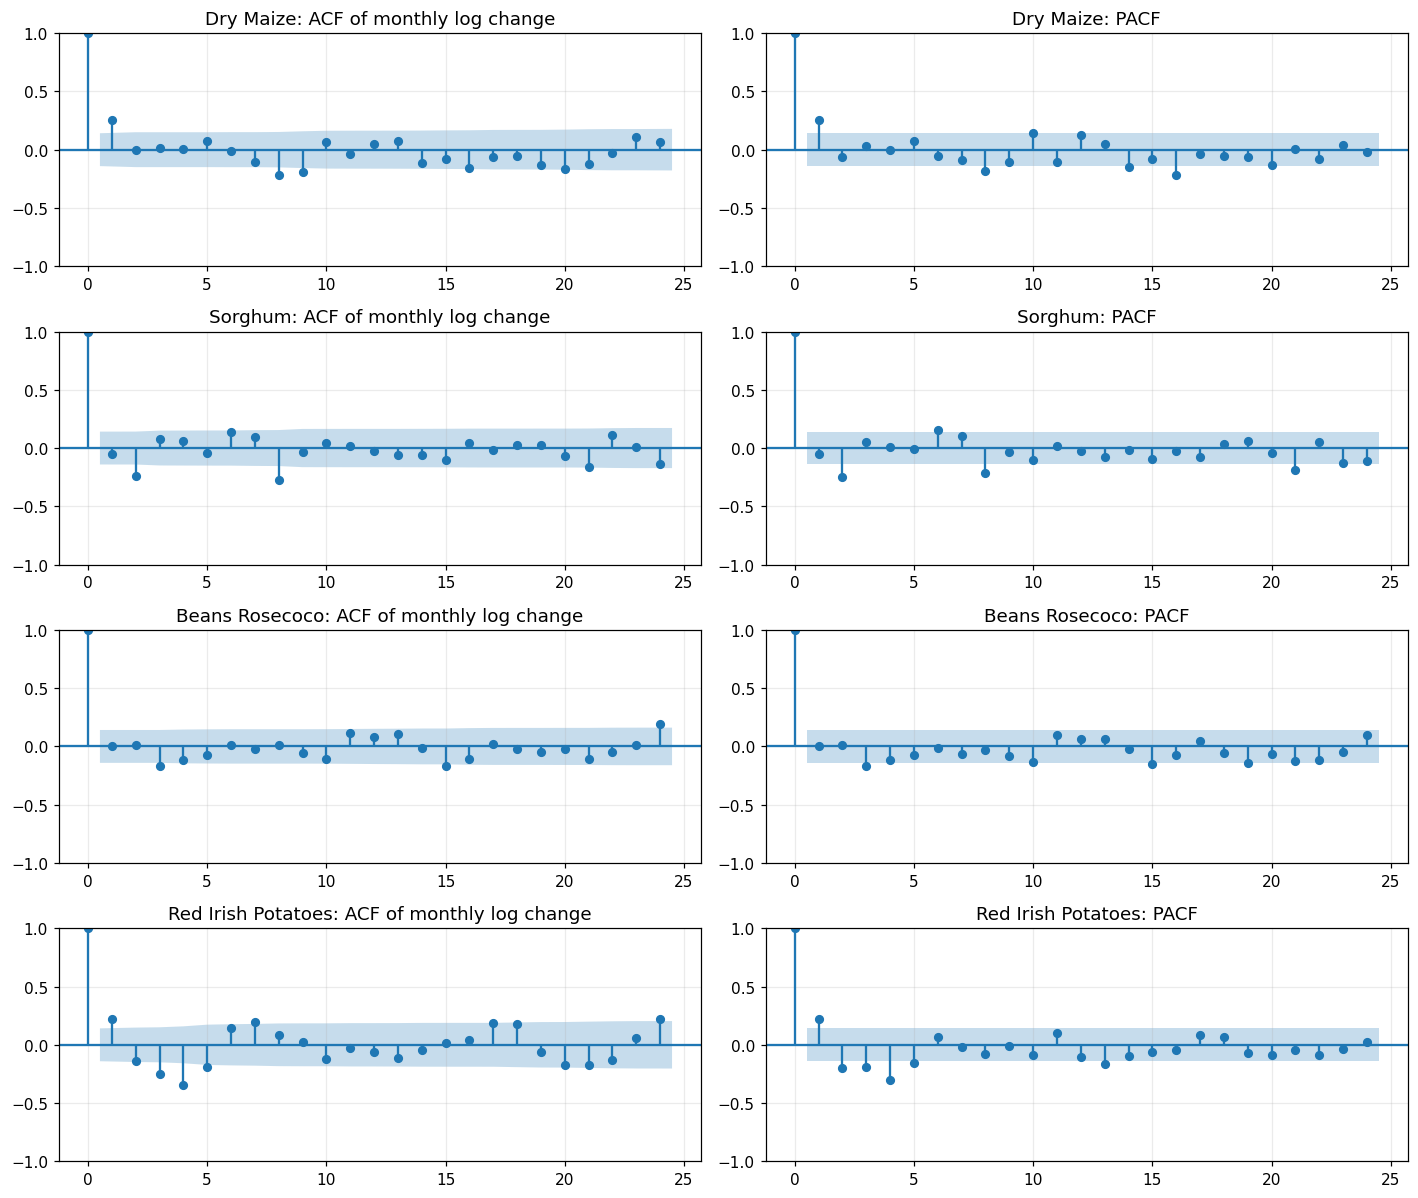

,ACF lag1,ACF lag2,ACF lag12,PACF lag1,PACF lag2,95% band,lags outside band,Ljung-Box p (6),Ljung-Box p (12),Ljung-Box p (24),reading
series,,,,,,,,,,,
Dry Maize,0.252,0.001,0.050,0.252,-0.067,0.141,"[1, 8, 9, 16, 20]",0.035,0.001,0.000,some structure in the changes
Sorghum,-0.049,-0.243,-0.029,-0.049,-0.246,0.141,"[2, 8, 21]",0.006,0.000,0.000,some structure in the changes
Beans Rosecoco,0.007,0.016,0.084,0.007,0.016,0.141,"[3, 15, 24]",0.157,0.171,0.022,random walk (changes are white noise)
Red Irish Potatoes,0.220,-0.139,-0.065,0.220,-0.197,0.141,"[1, 3, 4, 5, 6, 7, 17, 18, 20, 21, 24]",0.000,0.000,0.000,some structure in the changes


In [4]:
# 3a. ACF and PACF of the monthly log change (the differenced series)
fig, axs = plt.subplots(4, 2, figsize=(13, 11))
for i, c in enumerate(CORE):
    d = Y[c].diff().dropna()
    plot_acf(d, lags=24, ax=axs[i, 0], title=f'{c}: ACF of monthly log change'); plot_pacf(d, lags=24, ax=axs[i, 1], title=f'{c}: PACF', method='ywm')
plt.tight_layout(); save('t03_acf_pacf.png'); plt.show()

# 3b. Numbers behind the plots + Ljung-Box test: H0 = the changes are white noise (=> the price is a random walk)
rows = []
for c in CORE:
    d = Y[c].diff().dropna(); n = len(d); band = 1.96/np.sqrt(n)
    ac, pc = acf(d, nlags=24), pacf(d, nlags=24, method='ywm')
    lb6 = acorr_ljungbox(d, lags=[6])['lb_pvalue'].iloc[0]; lb12 = acorr_ljungbox(d, lags=[12])['lb_pvalue'].iloc[0]; lb24 = acorr_ljungbox(d, lags=[24])['lb_pvalue'].iloc[0]
    sig = [k for k in range(1, 25) if abs(ac[k]) > band]
    rows.append({'series': c, 'ACF lag1': ac[1], 'ACF lag2': ac[2], 'ACF lag12': ac[12], 'PACF lag1': pc[1], 'PACF lag2': pc[2], '95% band': band,
                 'lags outside band': sig, 'Ljung-Box p (6)': lb6, 'Ljung-Box p (12)': lb12, 'Ljung-Box p (24)': lb24,
                 'reading': 'random walk (changes are white noise)' if lb12 > .05 else 'some structure in the changes'})
AC = pd.DataFrame(rows).set_index('series'); display(AC.round(3))

**What it shows:** ACF and PACF bars for each series' monthly log change, and the numbers behind them.

**Insight:**
- **Maize:** lag-1 ACF = **0.25** (outside the band) and Ljung-Box p(12) = 0.001. There is a small *momentum*: a rise tends to be followed by a smaller rise.
- **Sorghum:** lag-2 ACF and PACF = **-0.24 / -0.25**, so there is a small reversal two months later (p < 0.001).
- **Potatoes:** lag-1 ACF = 0.22 and many lags outside the band (p < 0.001). The most structure, and the noisiest series.
- **Beans:** lag-1 ACF = 0.007 and Ljung-Box p(12) = 0.17. The changes are **white noise**: beans behave like a pure random walk.
- **No yearly cycle in the changes:** lag-12 ACF is between -0.07 and 0.08 for all four.

**What it means for SokoRadar:** The most structure we can hope to use is a low-order AR/MA term on the monthly change (momentum in maize and potatoes). Any gain over "same as last month" will be small. Beans need nothing more than the naive forecast.

## 4. Preprocessing decisions
The table turns the evidence from sections 1 to 3 into decisions, one row per series:
- **log transform:** kept for all four series so errors are percentages; the column "log steadies the spread?" shows where it is a real fix;
- **differencing d:** 1 if the log level is not stationary;
- **seasonal differencing D:** 1 only if seasonal strength is above 0.5 (otherwise the seasonal term would add noise);
- **white-noise changes?** "yes" means a random walk is already enough.

In [5]:
# 4. Preprocessing decisions, taken from the evidence above (not assumed)
dec = []; VR = pd.DataFrame(vr).set_index('series')
for c in CORE:
    v = ST[(ST.series == c)].set_index('version').verdict
    log_helps = abs(np.log(VR.loc[c, 'ratio (log)'])) < abs(np.log(VR.loc[c, 'ratio (level)']))     # closer to a ratio of 1 = steadier spread
    d_needed = v['log level'] != 'stationary'
    D_needed = CH.loc[c, 'seasonal strength'] > 0.5
    dec.append({'series': c, 'log steadies the spread?': 'yes' if log_helps else 'no', 'log used': 'yes (percent errors, comparable series)', 'log-level stationary?': v['log level'],
                'differencing d': 1 if d_needed else 0, 'seasonal strength': round(CH.loc[c, 'seasonal strength'], 2), 'seasonal differencing D': 1 if D_needed else 0,
                'white-noise changes?': 'yes' if AC.loc[c, 'Ljung-Box p (12)'] > .05 else 'no'})
DEC = pd.DataFrame(dec).set_index('series'); display(DEC)

,log steadies the spread?,log used,log-level stationary?,differencing d,seasonal strength,seasonal differencing D,white-noise changes?
series,,,,,,,
Dry Maize,yes,"yes (percent errors, comparable series)",mixed,1,0.02,0,no
Sorghum,no,"yes (percent errors, comparable series)",non-stationary,1,0.06,0,no
Beans Rosecoco,yes,"yes (percent errors, comparable series)",non-stationary,1,0.31,0,yes
Red Irish Potatoes,yes,"yes (percent errors, comparable series)",non-stationary,1,0.18,0,no


**Insight:**
- **d = 1 for all four series**, **D = 0 for all four** (seasonal strength is at most 0.31).
- The log steadies the spread for maize, beans and potatoes; sorghum does not need it but is kept in logs for comparability.
- **Beans have white-noise changes**, so for beans the right model is a random walk.

**What it means for SokoRadar:** We fit ARIMA-type models with **d = 1** and test seasonal terms in SARIMA only to check whether they earn their cost. We do not expect them to.

## 5. The model zoo
All models forecast the **log price** 1, 2 and 3 months ahead.

| Model | Idea | How it is built here |
|---|---|---|
| **White noise** | No pattern: the price scatters around a constant level | Forecast = average log price (a floor, to show the data are not white noise) |
| **Random walk (naive)** | Next value = last value + random shock | Forecast = last value |
| **Random walk + drift** | Same, plus a steady average rise | Last value + average monthly change |
| **AR(p)** | Past values drive the next one | ARMA with no MA term, fitted on the monthly change |
| **MA(q)** | Past forecast errors drive the next one | ARMA with no AR term, fitted on the monthly change |
| **ARMA(p,q)** | Both | Fitted on the monthly change, with a constant |
| **ARIMA(p,1,q)** | ARMA after one difference of the log price | Fitted on the log price, no drift |
| **SARIMA** | ARIMA plus a 12-month seasonal term | Four seasonal candidates, fitted on the log price |

AR, MA and ARMA are fitted on the monthly change and the changes are then added up, so they are close cousins of ARIMA (the main difference is the drift term).
**Choosing the order without cheating:** for each series and family we pick the order with the lowest **BIC on 2006-2012 only**, then freeze it and never touch it again. The 2013-2022 walk-forward is therefore a fair out-of-sample test.

In [6]:
# 5a. The model zoo. Everything is fitted to the LOG price, so forecast errors are in log points (about percent / 100).
H = 3
def fit_fc(spec, y, h=H):
    """y = numpy array of log prices up to the forecast origin. Returns h forecasts of the log price."""
    k = spec['kind']
    if k == 'naive':  return np.repeat(y[-1], h)                                   # random walk, no drift
    if k == 'snaive': return np.array([y[-12 + j] for j in range(h)])               # same month last year
    if k == 'rwd':    return y[-1] + np.diff(y).mean() * np.arange(1, h + 1)        # random walk with drift
    if k == 'wn':     return np.repeat(y.mean(), h)                                 # white noise around a constant level
    if k in ('AR', 'MA', 'ARMA'):                                                    # ARMA on the monthly change, then add the changes up
        r = ARIMA(np.diff(y), order=spec['order'], trend='c').fit(); return y[-1] + np.cumsum(r.forecast(h))
    if k == 'ARIMA':  return ARIMA(y, order=spec['order'], trend='n').fit().forecast(h)
    if k == 'SARIMA':
        r = SARIMAX(y, order=spec['order'], seasonal_order=spec['seasonal'], trend='n', enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=60)
        return r.forecast(h)
    raise ValueError(k)

def fit_ic(spec, y):
    """AIC, BIC and residuals of a fitted model."""
    k = spec['kind']
    if k in ('AR', 'MA', 'ARMA'): r = ARIMA(np.diff(y), order=spec['order'], trend='c').fit()
    elif k == 'ARIMA':            r = ARIMA(y, order=spec['order'], trend='n').fit()
    else: r = SARIMAX(y, order=spec['order'], seasonal_order=spec['seasonal'], trend='n', enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=60)
    return r.aic, r.bic, np.asarray(r.resid)

GRID = {'AR':    [{'kind': 'AR',  'order': (p, 0, 0)} for p in (1, 2, 3)],
        'MA':    [{'kind': 'MA',  'order': (0, 0, q)} for q in (1, 2, 3)],
        'ARMA':  [{'kind': 'ARMA', 'order': (p, 0, q)} for p in (1, 2) for q in (1, 2)],
        'ARIMA': [{'kind': 'ARIMA', 'order': (p, 1, q)} for p in (0, 1, 2) for q in (0, 1, 2) if (p, q) != (0, 0)],
        'SARIMA': [{'kind': 'SARIMA', 'order': o, 'seasonal': s} for o, s in [((1,1,1),(0,0,1,12)), ((1,1,0),(1,0,0,12)), ((0,1,1),(0,1,1,12)), ((1,1,1),(1,0,0,12))]]}

# 5b. Choose the order of each family by BIC on the FIRST 7 YEARS ONLY (2006-2012), then freeze it. No peeking at the evaluation years.
DEV_N = 84
SEL, rows = {}, []
for c in CORE:
    y_dev = Y[c].values[:DEV_N]
    for fam, specs in GRID.items():
        best = None
        for sp in specs:
            try: aic, bic, _ = fit_ic(sp, y_dev)
            except Exception: continue
            if best is None or bic < best[1]: best = (sp, bic, aic)
        SEL[(c, fam)] = best[0]
        rows.append({'series': c, 'family': fam, 'chosen order': best[0]['order'], 'seasonal': best[0].get('seasonal', ''), 'BIC (dev)': best[1], 'AIC (dev)': best[2]})
display(pd.DataFrame(rows).set_index(['series', 'family']).round(1))

chosen order       seasonal  BIC (dev)  AIC (dev)
series             family                                                  
Dry Maize          AR        (1, 0, 0)                    -160.4     -167.6
                   MA        (0, 0, 1)                    -159.5     -166.8
                   ARMA      (1, 0, 1)                    -156.2     -165.9
                   ARIMA     (1, 1, 0)                    -164.2     -169.0
                   SARIMA    (1, 1, 0)  (1, 0, 0, 12)     -128.8     -135.5
Sorghum            AR        (2, 0, 0)                    -139.6     -149.3
                   MA        (0, 0, 2)                    -138.7     -148.4
                   ARMA      (2, 0, 1)                    -135.2     -147.3
                   ARIMA     (2, 1, 0)                    -142.7     -150.0
                   SARIMA    (1, 1, 0)  (1, 0, 0, 12)     -117.7     -124.4
Beans Rosecoco     AR        (1, 0, 0)                    -178.1     -185.3
                   MA        (0, 0, 1)                    -178.1     -185.3
                   ARMA      (2, 0, 2)                    -178.6     -193.2
                   ARIMA     (2, 1, 2)                    -182.7     -194.8
                   SARIMA    (1, 1, 0)  (1, 0, 0, 12)     -155.6     -162.4
Red Irish Potatoes AR        (2, 0, 0)                     -50.3      -60.0
                   MA        (0, 0, 3)                     -55.7      -67.8
                   ARMA      (2, 0, 1)                     -62.2      -74.3
                   ARIMA     (2, 1, 1)                     -59.6      -69.3
                   SARIMA    (1, 1, 0)  (1, 0, 0, 12)      -60.6      -67.4

**Insight:**
- Low orders are enough: ARIMA(1,1,0) for maize, (2,1,0) for sorghum, (2,1,2) for beans, (2,1,1) for potatoes.
- On the development years the seasonal term was the weakest candidate for maize, sorghum and beans (for maize its BIC is -128.8 against -164.2 for ARIMA), consistent with the weak seasonality found in section 1. Potatoes were the only near tie.

**What it means for SokoRadar:** The data support simple models. A big, flexible time-series model would only fit noise.

## 6. Walk-forward accuracy: MAE and RMSE
**How it works:** at each origin (every quarter from Dec 2012 to Sep 2021, 36 origins) we refit each model on all history up to that month, forecast 1, 2 and 3 months ahead, and compare with what happened. This mimics real use: the model only ever sees the past.
- **MAE** (mean absolute error): the average size of a miss, in log points (0.10 is about 10%).
- **RMSE** (root mean squared error): like MAE but squares the misses first, so it punishes **large** misses more.
- **vs naive %:** the change in error relative to "same as last month". Negative = better than naive.
- **Seconds per fit:** the computation cost the supervisor asked about.

origins per series: 36 | first origin 2012-12 | last origin 2021-09 | failed fits: 0


MAE                 RMSE               MAE vs naive %  \
h                        1      2      3      1      2      3              1   
model                                                                          
white noise          0.314  0.321  0.313  0.358  0.365  0.357        321.693   
naive                0.074  0.115  0.132  0.110  0.181  0.218          0.000   
seasonal naive       0.216  0.219  0.211  0.324  0.290  0.312        189.602   
random walk + drift  0.075  0.116  0.134  0.110  0.182  0.220          0.281   
AR                   0.081  0.120  0.139  0.114  0.190  0.223          8.182   
MA                   0.084  0.120  0.141  0.121  0.184  0.211         13.274   
ARMA                 0.081  0.119  0.150  0.113  0.175  0.219          9.220   
ARIMA                0.080  0.115  0.134  0.112  0.174  0.206          6.972   
SARIMA               0.078  0.117  0.139  0.113  0.188  0.231          4.322   

                                       
h                          2        3  
model                                  
white noise          179.352  137.179  
naive                  0.000    0.000  
seasonal naive        90.884   59.721  
random walk + drift    1.262    1.323  
AR                     4.328    5.336  
MA                     4.490    6.629  
ARMA                   3.487   13.696  
ARIMA                 -0.057    1.662  
SARIMA                 2.190    5.040

,seconds per fit
model,
white noise,0.0000
naive,0.0000
seasonal naive,0.0000
random walk + drift,0.0000
AR,0.0929
MA,0.1730
ARMA,0.3273
ARIMA,0.1880
SARIMA,0.1407


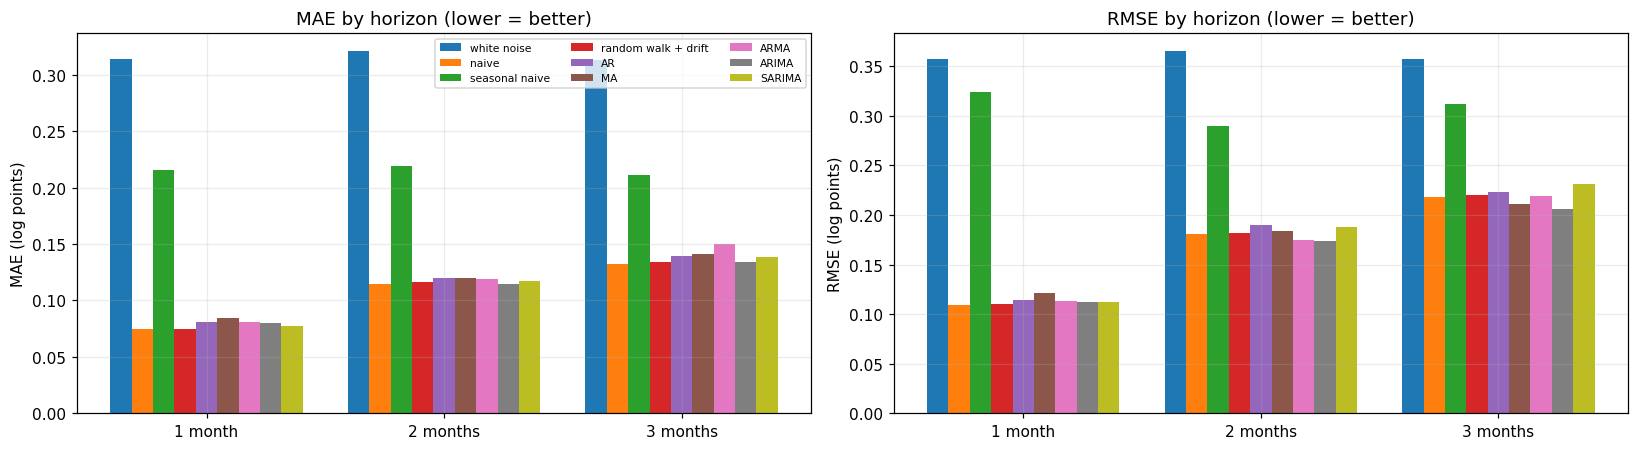

,white noise,seasonal naive,random walk + drift,AR,MA,ARMA,ARIMA,SARIMA
"share of origins beating naive, h=3",,,,,,,,
Beans Rosecoco,0.08,0.33,0.47,0.47,0.47,0.50,0.61,0.64
Dry Maize,0.14,0.36,0.50,0.42,0.50,0.39,0.42,0.42
Red Irish Potatoes,0.36,0.36,0.44,0.42,0.36,0.39,0.44,0.42
Sorghum,0.00,0.25,0.50,0.47,0.39,0.47,0.47,0.53


model,white noise,naive,seasonal naive,random walk + drift,AR,MA,ARMA,ARIMA,SARIMA
MAE at 3 months by series,,,,,,,,,
Beans Rosecoco,0.268,0.095,0.140,0.097,0.097,0.097,0.098,0.095,0.092
Dry Maize,0.270,0.122,0.199,0.123,0.126,0.124,0.126,0.125,0.126
Red Irish Potatoes,0.350,0.245,0.364,0.248,0.262,0.269,0.305,0.249,0.271
Sorghum,0.366,0.067,0.142,0.068,0.072,0.073,0.071,0.068,0.066


In [7]:
# 6. Walk-forward evaluation on the real window: refit every quarter on all data up to the origin, forecast 1, 2 and 3 months ahead.
FAMS = ['white noise', 'naive', 'seasonal naive', 'random walk + drift', 'AR', 'MA', 'ARMA', 'ARIMA', 'SARIMA']
def spec_for(c, fam):
    base = {'white noise': {'kind': 'wn'}, 'naive': {'kind': 'naive'}, 'seasonal naive': {'kind': 'snaive'}, 'random walk + drift': {'kind': 'rwd'}}
    return base[fam] if fam in base else SEL[(c, fam)]
origins = list(range(DEV_N - 1, len(Y) - H, 3))
rec = []; fails = 0
for c in CORE:
    y = Y[c].values
    for fam in FAMS:
        sp = spec_for(c, fam)
        for i in origins:
            t0 = time.perf_counter()
            try: f = fit_fc(sp, y[:i + 1])
            except Exception: f = np.full(H, np.nan); fails += 1
            dt = time.perf_counter() - t0
            for h in range(1, H + 1):
                rec.append({'series': c, 'model': fam, 'origin': i, 'h': h, 'err': y[i + h] - f[h - 1], 'sec': dt})
WF = pd.DataFrame(rec)
print('origins per series:', len(origins), '| first origin', Y.index[origins[0]], '| last origin', Y.index[origins[-1]], '| failed fits:', fails)
def metrics(df):
    g = df.groupby(['model', 'h']).agg(MAE=('err', lambda e: e.abs().mean()), RMSE=('err', lambda e: np.sqrt((e**2).mean())), n=('err', 'size'), sec_per_fit=('sec', 'mean'))
    return g
MET = metrics(WF)
nv = MET.xs('naive', level='model')
MET['MAE vs naive %'] = [100*(m.MAE/nv.loc[h, 'MAE'] - 1) for (mod, h), m in MET.iterrows()]
MET['RMSE vs naive %'] = [100*(m.RMSE/nv.loc[h, 'RMSE'] - 1) for (mod, h), m in MET.iterrows()]
T = MET.reset_index().pivot(index='model', columns='h', values=['MAE', 'RMSE', 'MAE vs naive %']).reindex(FAMS)
display(T.round(3))
display(MET.groupby('model').sec_per_fit.mean().reindex(FAMS).rename('seconds per fit').round(4).to_frame())

fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), sharey=False)
for ax, m_ in zip(axs, ['MAE', 'RMSE']):
    for k, fam in enumerate(FAMS):
        ax.bar(np.arange(3) + (k - 4)*0.09, [MET.loc[(fam, h), m_] for h in (1, 2, 3)], 0.09, label=fam)
    ax.set_xticks(range(3)); ax.set_xticklabels(['1 month', '2 months', '3 months']); ax.set_ylabel(m_ + ' (log points)'); ax.set_title(m_ + ' by horizon (lower = better)')
axs[0].legend(fontsize=7, ncol=3); plt.tight_layout(); save('t04_model_errors.png'); plt.show()

# per-series view at 3 months, and how often each model beats naive on the same origin
wide = WF.pivot_table(index=['series', 'h', 'origin'], columns='model', values='err')
win = {fam: (wide[fam].abs() < wide['naive'].abs()).groupby(level=['series', 'h']).mean() for fam in FAMS if fam != 'naive'}
display(pd.DataFrame(win).xs(3, level='h').round(2).rename_axis('share of origins beating naive, h=3'))
display(WF[WF.h == 3].groupby(['series', 'model']).err.apply(lambda e: e.abs().mean()).unstack()[FAMS].round(3).rename_axis('MAE at 3 months by series'))

**What it shows:** error by model and horizon (bars), the exact numbers, how often each model beats naive on the same origin, and MAE by series at 3 months.

**Insight:**
- **Naive is very hard to beat.** Its MAE is 0.074, 0.115, 0.132 at 1, 2 and 3 months (about 7%, 12% and 13%).
- **No model beats naive on MAE.** ARIMA is the closest: +7.1%, -0.1% and +1.9% against naive. Random walk + drift is +0.3% to +1.3% worse; AR +4% to +8%; MA +4% to +13%; ARMA +3% to +14%; SARIMA +2% to +5%.
- **On RMSE, ARIMA does slightly better at 2 and 3 months** (0.174 vs 0.181 and 0.206 vs 0.218, about 4% and 5% lower). So it avoids some large misses even though its typical miss is no smaller.
- **The two simple "no-skill" models are far worse:** seasonal naive is +190%, +91% and +60% against naive; white noise is +137% to +322%. The series are not white noise, and "same as last year" is a poor forecast.
- **By series (3 months):** ARIMA beats naive on 64% of origins for beans but only 42 to 47% for maize, sorghum and potatoes. SARIMA is marginally best on beans (0.092 vs 0.095) and sorghum (0.066 vs 0.067), a difference of a few thousandths.
- **Cost:** every model fits in under 0.1 second.
- **Caution:** 36 origins and four series. Differences of 1 to 3% are within noise.

**What it means for SokoRadar:** Classic univariate models tie with naive. Beating naive needs information **outside** the price history, such as rainfall, vegetation and the bean-to-maize lead-lag. That is what notebook 02 uses.

## 7. AIC, BIC and residual checks
- **AIC** and **BIC** score a model by fit minus a penalty for complexity. **Lower is better.** BIC penalises extra parameters more, so it favours simpler models. Differences below about 2 are ties. AR, MA and ARMA are fitted on the monthly change while ARIMA and SARIMA are fitted on the level, so compare within a series, and treat cross-family gaps as a guide.
- **Residual check (Ljung-Box, 12 lags):** if the leftover errors are white noise, the model has captured the structure. If not, something is missing.
- **Best family** here means the one with the smallest average MAE change against naive across the three horizons.

order       seasonal     AIC     BIC  \
series             family                                             
Dry Maize          AR      (1, 0, 0)                -406.60 -396.81   
                   MA      (0, 0, 1)                -407.66 -397.87   
                   ARMA    (1, 0, 1)                -405.68 -392.63   
                   ARIMA   (1, 1, 0)                -408.21 -401.69   
                   SARIMA  (1, 1, 0)  (1, 0, 0, 12) -374.92 -365.34   
Sorghum            AR      (2, 0, 0)                -446.23 -433.18   
                   MA      (0, 0, 2)                -444.55 -431.50   
                   ARMA    (2, 0, 1)                -444.68 -428.37   
                   ARIMA   (2, 1, 0)                -446.33 -436.55   
                   SARIMA  (1, 1, 0)  (1, 0, 0, 12) -422.10 -412.53   
Beans Rosecoco     AR      (1, 0, 0)                -456.46 -446.67   
                   MA      (0, 0, 1)                -456.46 -446.67   
                   ARMA    (2, 0, 2)                -459.86 -440.28   
                   ARIMA   (2, 1, 2)                -460.89 -444.57   
                   SARIMA  (1, 1, 0)  (1, 0, 0, 12) -435.78 -426.20   
Red Irish Potatoes AR      (2, 0, 0)                 -90.59  -77.54   
                   MA      (0, 0, 3)                 -99.71  -83.39   
                   ARMA    (2, 0, 1)                -112.71  -96.39   
                   ARIMA   (2, 1, 1)                -113.84 -100.79   
                   SARIMA  (1, 1, 0)  (1, 0, 0, 12)  -87.44  -77.86   

                           residual Ljung-Box p residuals white?  
series             family                                         
Dry Maize          AR                      0.04               no  
                   MA                      0.05              yes  
                   ARMA                    0.05              yes  
                   ARIMA                   0.04               no  
                   SARIMA                  0.05               no  
Sorghum            AR                      0.10              yes  
                   MA                      0.07              yes  
                   ARMA                    0.12              yes  
                   ARIMA                   0.07              yes  
                   SARIMA                  0.00               no  
Beans Rosecoco     AR                      0.26              yes  
                   MA                      0.26              yes  
                   ARMA                    0.49              yes  
                   ARIMA                   0.51              yes  
                   SARIMA                  0.50              yes  
Red Irish Potatoes AR                      0.00               no  
                   MA                      0.01               no  
                   ARMA                    0.21              yes  
                   ARIMA                   0.21              yes  
                   SARIMA                  0.00               no

,"mean MAE vs naive %, all horizons"
model,
ARIMA,2.86
SARIMA,3.85
AR,5.95
MA,8.13
ARMA,8.80


Best family on the real window: ARIMA | mean change vs naive: 2.86 %


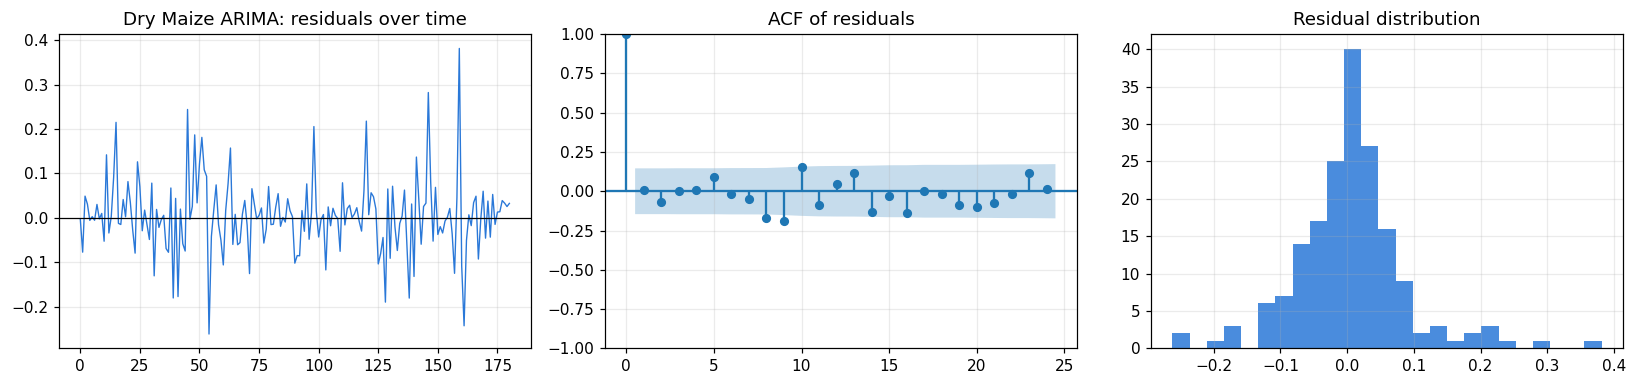

In [8]:
# 7a. Full-window fit: AIC, BIC and a residual white-noise test (Ljung-Box, 12 lags) for each chosen model
rows = []
for c in CORE:
    y = Y[c].values
    for fam in ['AR', 'MA', 'ARMA', 'ARIMA', 'SARIMA']:
        sp = SEL[(c, fam)]
        try:
            aic, bic, res = fit_ic(sp, y); res = res[13:] if len(res) > 20 else res
            lb = acorr_ljungbox(res, lags=[12])['lb_pvalue'].iloc[0]
            rows.append({'series': c, 'family': fam, 'order': sp['order'], 'seasonal': sp.get('seasonal', ''), 'AIC': aic, 'BIC': bic, 'residual Ljung-Box p': lb, 'residuals white?': 'yes' if lb > .05 else 'no'})
        except Exception as e: rows.append({'series': c, 'family': fam, 'order': sp['order'], 'AIC': np.nan, 'BIC': np.nan})
IC = pd.DataFrame(rows).set_index(['series', 'family']); display(IC.round(2))

# 7b. Which family is best overall? Average of the % change in MAE versus naive across horizons (negative = better than naive)
cand = ['AR', 'MA', 'ARMA', 'ARIMA', 'SARIMA']        # the fitted families (benchmarks are shown in the table above)
score = MET.reset_index().query('model in @cand').groupby('model')['MAE vs naive %'].mean().sort_values()
display(score.round(2).rename('mean MAE vs naive %, all horizons').to_frame())
BEST = score.index[0]; print('Best family on the real window:', BEST, '| mean change vs naive:', round(score.iloc[0], 2), '%')

# 7c. Residual check of the best family for maize
c0 = 'Dry Maize'; _, _, res0 = fit_ic(SEL[(c0, BEST)], Y[c0].values); res0 = res0[13:]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
axs[0].plot(res0, color=BLUE, lw=.9); axs[0].axhline(0, c='k', lw=.8); axs[0].set_title(f'{c0} {BEST}: residuals over time')
plot_acf(res0, lags=24, ax=axs[1], title='ACF of residuals'); axs[2].hist(res0, bins=25, color=BLUE, alpha=.85); axs[2].set_title('Residual distribution')
plt.tight_layout(); save('t05_residuals.png'); plt.show()

**What it shows:** a table of AIC, BIC and residual tests for each chosen model, the family ranking, and residual plots for maize.

**Insight:**
- **ARIMA has the best (lowest) BIC** for maize (-401.7 vs -396.8 for AR), sorghum (-436.6) and potatoes (-100.8), and the best AIC for all three. For beans, BIC prefers the simple AR(1) (-446.7 vs -444.7), consistent with beans being almost a random walk.
- **SARIMA always scores worse** (for example maize BIC -365.3 against -401.7). The seasonal term does not earn its cost.
- **Residuals:** ARMA/ARIMA residuals are white for sorghum, beans and potatoes (Ljung-Box p between 0.07 and 0.49). For maize they sit right at the edge (p = 0.04 to 0.05), so a little structure is left.
- **Ranking by walk-forward error:** ARIMA (+3.0% vs naive) < SARIMA (+3.9%) < AR (+6.0%) < MA (+8.1%) < ARMA (+8.7%). **ARIMA is the best family on the real window**, and none beats naive on average.

**What it means for SokoRadar:** If we use a time-series model at all, use a low-order **ARIMA(p,1,q)**. Seasonal terms are not worth adding.

## 8. [EST] vs [REAL]: do estimated national months change the answer?
The group rule is to include estimated prices and label them. Here we repeat the walk-forward on the **full 2006-2024 national series**, which includes the estimated months from March 2022. We split the results by whether the **target month** is real or estimated. Negative "gain" means worse than naive.

In [9]:
# 8. [EST] vs [REAL]: the same walk-forward, but running on to 2024-12 so it includes the estimated national months.
Yfull = np.log(P.loc[WIN[0]:pd.Period(TRAIN[1]), CORE])
est_start = len(Y)                                      # first estimated month position
orig_f = list(range(DEV_N - 1, len(Yfull) - H, 3)); rec = []
for c in CORE:
    y = Yfull[c].values
    for fam in ['naive', 'random walk + drift', BEST]:
        sp = spec_for(c, fam)
        for i in orig_f:
            try: f = fit_fc(sp, y[:i + 1])
            except Exception: f = np.full(H, np.nan)
            for h in range(1, H + 1):
                rec.append({'series': c, 'model': fam, 'origin': i, 'h': h, 'err': y[i + h] - f[h - 1], 'target_real': (i + h) < est_start})
EV = pd.DataFrame(rec)
tab = EV.groupby(['target_real', 'model', 'h']).err.apply(lambda e: e.abs().mean()).unstack('h')
tab.index = tab.index.set_levels(['[EST] target is estimated', '[REAL] target is real'], level=0); display(tab.round(3))
g = EV.groupby(['target_real', 'model']).err.apply(lambda e: e.abs().mean()).unstack('model')
g['gain of ' + BEST + ' vs naive %'] = 100*(1 - g[BEST]/g['naive']); g.index = ['[EST] estimated targets', '[REAL] real targets']; display(g.round(3))

h                                                  1      2      3
target_real               model                                   
[EST] target is estimated ARIMA                0.084  0.099  0.145
                          naive                0.086  0.097  0.133
                          random walk + drift  0.087  0.099  0.132
[REAL] target is real     ARIMA                0.078  0.113  0.134
                          naive                0.073  0.113  0.132
                          random walk + drift  0.073  0.114  0.134

model,ARIMA,naive,random walk + drift,gain of ARIMA vs naive %
[EST] estimated targets,0.110,0.106,0.107,-4.074
[REAL] real targets,0.108,0.106,0.107,-2.021


**Insight:**
- **The conclusion does not change.** ARIMA is 2.2% worse than naive on real targets and 3.2% worse on estimated targets. Random walk + drift is about 1% worse in both.
- **Estimated months are not smoother here.** The one-month naive error is 0.086 on estimated targets against 0.073 on real targets. The estimated series contains big jumps (for example the April 2023 peak near 87 KES/kg), so estimates add noise rather than hiding it.
- Overall naive MAE is almost the same (0.106) either way.

**What it means for SokoRadar:** Report time-series results on the **[REAL]** window and show the [EST] row beside it. The finding "ARIMA does not beat naive" holds on both. National 2023-24 prices should not be used to score a model.

## 9. Held-out test on real county markets (2025-01 to 2026-09)
This is the group's real test: WFP county market prices after the training period. For each market series we use the **same model family and order that was chosen on the national series of the same crop** (maize to Dry Maize, beans to Beans Rosecoco, potatoes to Red Irish Potatoes), refit it at every month of the test period on all history so far, and forecast 1 to 3 months ahead. Only months with a real observed price at both the origin and the target are scored.
**Which series qualify:** at least 24 observed months in one block (gaps of 3 months or fewer, filled by interpolation in the *history* only) and at least 6 test months. That leaves **9 series**, all Daadab and Kakuma refugee-camp retail markets: 4 beans, 3 potatoes, 2 maize and **no sorghum**. The long wholesale series do not report in 2025-26.

In [10]:
# 9. Test on the real held-out period 2025-01 to 2026-09 using WFP county market series (the group's test set).
# Same model family and orders as chosen on the national real window for the matching crop; refit every origin on all history.
CROP2SERIES = {'Maize': 'Dry Maize', 'Beans': 'Beans Rosecoco', 'Potatoes': 'Red Irish Potatoes', 'Sorghum': 'Sorghum'}
t_lo, t_hi = pd.Period(TEST[0]), pd.Period(TEST[1])
def market_blocks():
    out = []
    for (adm, mk, cr, pt), g in led.groupby(['admin2', 'market', 'crop', 'pricetype']):
        s = np.log(g.set_index('month').kes_kg.sort_index()); full = pd.period_range(s.index.min(), t_hi, freq='M'); sf = s.reindex(full)
        nan = sf.isna().values; start = 0; run = 0
        for i, v in enumerate(nan):
            if v: run += 1
            else:
                if run > 3: start = i
                run = 0
        blk = sf.iloc[start:]
        blk = blk.iloc[:len(blk) - int(np.argmax(~blk.isna().values[::-1]))] if blk.notna().any() else blk   # drop trailing NaNs
        obs = blk.notna(); tr_n = int(obs.loc[:pd.Period(TRAIN[1])].sum()); te_n = int(obs.loc[t_lo:].sum())
        if tr_n >= 24 and te_n >= 6: out.append(dict(market=mk, county=adm, crop=cr, pricetype=pt, train_obs=tr_n, test_obs=te_n, raw=blk, y=blk.interpolate(limit=3, limit_area='inside')))
    return out
MB = market_blocks()
print('Qualifying market series (24+ train months in one block with gaps of 3 months or less, 6+ test months):', len(MB), '| by crop:', pd.Series([m['crop'] for m in MB]).value_counts().to_dict())

rec = []
for m in MB:
    sp_best = spec_for(CROP2SERIES[m['crop']], BEST); y_all = m['y']; raw = m['raw']
    for i, per in enumerate(y_all.index):
        if per < t_lo or pd.isna(raw.iloc[i]) or y_all.iloc[:i+1].isna().any(): continue
        hist = y_all.iloc[:i + 1].values
        for fam, sp in (('naive', {'kind': 'naive'}), ('random walk + drift', {'kind': 'rwd'}), (BEST, sp_best)):
            t0 = time.perf_counter()
            try: f = fit_fc(sp, hist)
            except Exception: f = np.full(H, np.nan)
            dt = time.perf_counter() - t0
            for h in range(1, H + 1):
                if i + h < len(raw) and not pd.isna(raw.iloc[i + h]):
                    rec.append({'market': m['market'], 'crop': m['crop'], 'model': fam, 'h': h, 'err': raw.iloc[i + h] - f[h - 1], 'sec': dt})
CT = pd.DataFrame(rec)
pool = CT.groupby(['model', 'h']).agg(MAE=('err', lambda e: e.abs().mean()), RMSE=('err', lambda e: np.sqrt((e**2).mean())), n=('err', 'size'), sec=('sec', 'mean'))
nvc = pool.xs('naive', level='model'); pool['MAE gain vs naive %'] = [100*(1 - r.MAE/nvc.loc[h, 'MAE']) for (mo, h), r in pool.iterrows()]
pool['RMSE gain vs naive %'] = [100*(1 - r.RMSE/nvc.loc[h, 'RMSE']) for (mo, h), r in pool.iterrows()]
display(pool.round(3))
bycrop = CT.groupby(['crop', 'model', 'h']).err.apply(lambda e: e.abs().mean()).unstack('model')
bycrop['gain of ' + BEST + ' %'] = 100*(1 - bycrop[BEST]/bycrop['naive']); display(bycrop.round(3))

Qualifying market series (24+ train months in one block with gaps of 3 months or less, 6+ test months): 9 | by crop: {'Beans': 4, 'Potatoes': 3, 'Maize': 2}


MAE   RMSE    n    sec  MAE gain vs naive %  \
model               h                                                  
ARIMA               1  0.087  0.122  143  0.158              -14.549   
                    2  0.110  0.150  132  0.158               -4.450   
                    3  0.120  0.161  125  0.155                6.985   
naive               1  0.076  0.114  143  0.000                0.000   
                    2  0.105  0.150  132  0.000                0.000   
                    3  0.129  0.178  125  0.000                0.000   
random walk + drift 1  0.077  0.116  143  0.000               -1.372   
                    2  0.108  0.155  132  0.000               -3.332   
                    3  0.136  0.187  125  0.000               -5.576   

                       RMSE gain vs naive %  
model               h                        
ARIMA               1                -6.445  
                    2                -0.078  
                    3                 9.400  
naive               1                 0.000  
                    2                 0.000  
                    3                 0.000  
random walk + drift 1                -1.587  
                    2                -3.259  
                    3                -5.204

model       ARIMA  naive  random walk + drift  gain of ARIMA %
crop     h                                                    
Beans    1  0.062  0.053                0.054          -15.751
         2  0.072  0.068                0.071           -5.377
         3  0.088  0.089                0.094            0.871
Maize    1  0.072  0.066                0.066           -9.332
         2  0.094  0.094                0.096           -0.130
         3  0.107  0.107                0.115            0.407
Potatoes 1  0.136  0.118                0.119          -15.828
         2  0.175  0.165                0.171           -5.591
         3  0.177  0.204                0.214           13.417

**What it shows:** pooled and per-crop error for naive, random walk + drift and ARIMA on real held-out months.

**Insight:**
- **ARIMA is worse than naive at 1 month** (MAE +15.0% higher error, i.e. a -15.0% gain; RMSE -6.6%), about even at 2 months (-4.5% MAE, -0.1% RMSE) and **better at 3 months** (+6.6% MAE, +9.3% RMSE).
- **Random walk + drift is worse than naive at every horizon** (-1.4%, -3.3%, -5.6%). Camp-market prices move in steps, not along a steady slope.
- **By crop at 3 months:** potatoes +13.4%, maize +0.4%, beans -0.2%. The pooled 3-month gain comes mostly from potatoes.
- **Sample:** 125 to 143 forecasts from 9 series, all camp markets in two counties (Garissa and Turkana). Treat the numbers as indicative.
- **Compared with notebook 02:** the ridge model there gained +2.0%, +4.4% and +9.4% (1, 2, 3 months) on about 30 series. The rows are not the same, so this is not a like-for-like contest, but the model that uses rain, vegetation and the lead crop scores better at every horizon, most clearly at 1 and 2 months.

**What it means for SokoRadar:** A univariate ARIMA is a fair benchmark, not the answer. It helps only at 3 months and only for potatoes. The gain must come from drivers and from pooling many markets.

## 10. Forecasting and automation
After validation, the model is used as a **monthly routine**:
1. **Refresh:** when new WFP prices arrive, re-run notebook 01 (it rewrites `handoff/`), then call `refresh_forecasts(MB)`. It refits each qualifying market series on all history, forecasts 1 to 3 months ahead with an **80% interval**, and writes `forecasts_latest.csv`.
2. **Rank and flag:** the `watch` column marks the top 20% of forecast rises at each horizon (the rank-based alert rule from notebook 02, because a fixed threshold almost never fires).
3. **Monitor:** compare the model with naive every month. If it loses to naive for 6 months in a row, **fall back to naive** and re-select orders.
4. **Re-evaluate on a schedule:** refit every month, re-pick orders every quarter with the walk-forward test from section 6, and re-check the stationarity and ACF diagnostics once a year.
5. **Automate:** the functions in this notebook can be moved into a script and run by a scheduler (for example a monthly cron job or GitHub Action) with no manual step.

Series forecast: 9 | as of 2026-09


,asof,market,county,crop,pricetype,h,last_price_kes_kg,forecast_kes_kg,change_%,low80_kes_kg,high80_kes_kg,watch
5,2026-09,Dagahaley (Daadab),Garissa,Potatoes,Retail,3,60.00,68.42,14.03,49.58,94.42,True
20,2026-09,IFO (Daadab),Garissa,Potatoes,Retail,3,64.39,71.06,10.36,50.32,100.35,True
26,2026-09,Kakuma 3,Turkana,Maize,Retail,3,59.90,61.43,2.56,47.57,79.34,False
11,2026-09,Hagadera (Daadab),Garissa,Potatoes,Retail,3,69.33,70.95,2.33,54.13,92.98,False
23,2026-09,Kakuma 3,Turkana,Beans,Retail,3,129.69,131.97,1.76,108.82,160.04,False
8,2026-09,Hagadera (Daadab),Garissa,Beans,Retail,3,119.17,120.99,1.52,106.24,137.78,False
2,2026-09,Dagahaley (Daadab),Garissa,Beans,Retail,3,114.06,114.21,0.13,96.25,135.51,False
14,2026-09,IFO (Daadab),Garissa,Beans,Retail,3,120.00,119.29,-0.59,103.50,137.48,False
17,2026-09,IFO (Daadab),Garissa,Maize,Retail,3,70.00,69.26,-1.05,57.34,83.67,False


saved C:\Users\dwtha\CAPSTONE2\handoff\forecasts_latest.csv


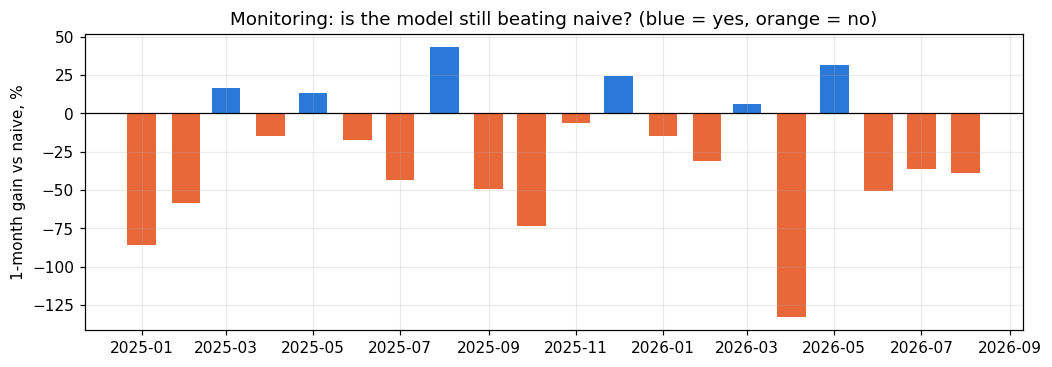

Months where the model lost to naive: 14 of 20


In [11]:
# 10. Forecasting and automation: refit on the latest data, forecast 1-3 months ahead with 80% intervals, rank, and save.
from scipy.stats import norm
def level_forecast(sp, y, h=H):
    """Mean and standard error of the log price for h steps (random-walk-type approximation for the AR/MA/ARMA families)."""
    k = sp['kind']
    if k in ('AR', 'MA', 'ARMA'):
        r = ARIMA(np.diff(y), order=sp['order'], trend='c').fit(); fc = r.get_forecast(h)
        return y[-1] + np.cumsum(fc.predicted_mean), np.sqrt(np.cumsum(fc.se_mean**2))
    if k == 'ARIMA': fc = ARIMA(y, order=sp['order'], trend='n').fit().get_forecast(h)
    elif k == 'SARIMA': fc = SARIMAX(y, order=sp['order'], seasonal_order=sp['seasonal'], trend='n', enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=60).get_forecast(h)
    else: return fit_fc(sp, y, h), np.full(h, np.nan)
    return fc.predicted_mean, fc.se_mean

def refresh_forecasts(blocks, asof=None, top_share=0.20):
    """One call = one monthly run. Returns a table with a forecast, an 80% interval and a watch flag per market series."""
    asof = asof or t_hi; rows = []
    for m in blocks:
        raw, y = m['raw'], m['y']
        if raw.index[-1] < asof - 2 or pd.isna(y.iloc[-1]): continue               # series must have reported in the last 3 months
        sp = spec_for(CROP2SERIES[m['crop']], BEST)
        try: mu, se = level_forecast(sp, y.values)
        except Exception: continue
        for h in range(1, H + 1):
            z = norm.ppf(.9); last = y.values[-1]
            rows.append({'asof': str(asof), 'market': m['market'], 'county': m['county'], 'crop': m['crop'], 'pricetype': m['pricetype'], 'h': h, 'last_price_kes_kg': float(np.exp(last)),
                         'forecast_kes_kg': float(np.exp(mu[h-1])), 'change_%': float(100*np.expm1(mu[h-1] - last)),
                         'low80_kes_kg': float(np.exp(mu[h-1] - z*se[h-1])), 'high80_kes_kg': float(np.exp(mu[h-1] + z*se[h-1]))})
    F = pd.DataFrame(rows)
    if len(F): F['watch'] = F.groupby('h')['change_%'].transform(lambda s: s >= s.quantile(1 - top_share))      # rank-based alert: top 20% of forecast rises
    return F
FC = refresh_forecasts(MB)
print('Series forecast:', FC[['market', 'crop', 'pricetype']].drop_duplicates().shape[0], '| as of', t_hi)
display(FC[FC.h == 3].sort_values('change_%', ascending=False).head(12).round(2))
OUT_FC = IN / 'forecasts_latest.csv'; FC.to_csv(OUT_FC, index=False); print('saved', OUT_FC)

# Monitoring: rolling error of the model vs naive, by test month. A negative gain for several months in a row means it is time to re-select orders.
mon = []
for m in MB:
    sp = spec_for(CROP2SERIES[m['crop']], BEST); raw, y = m['raw'], m['y']
    for i, per in enumerate(y.index):
        if per < t_lo or pd.isna(raw.iloc[i]) or i + 1 >= len(raw) or pd.isna(raw.iloc[i + 1]): continue
        try: f = fit_fc(sp, y.iloc[:i + 1].values, 1)[0]
        except Exception: continue
        mon.append({'month': per, 'naive': abs(raw.iloc[i + 1] - raw.iloc[i]), 'model': abs(raw.iloc[i + 1] - f)})
MON = pd.DataFrame(mon).groupby('month').mean(); MON['gain_%'] = 100*(1 - MON.model/MON.naive)
fig, ax = plt.subplots(figsize=(11, 3.5)); ax.bar(MON.index.to_timestamp(), MON['gain_%'], width=20, color=[BLUE if g > 0 else ORANGE for g in MON['gain_%']]); ax.axhline(0, c='k', lw=.8)
ax.set_ylabel('1-month gain vs naive, %'); ax.set_title('Monitoring: is the model still beating naive? (blue = yes, orange = no)'); save('t06_monitoring.png'); plt.show()
print('Months where the model lost to naive:', int((MON['gain_%'] < 0).sum()), 'of', len(MON))

**What it shows:** the forecast table as of the latest month, with 80% intervals, and a bar chart of the model's one-month gain over naive for each test month.

**Insight:**
- Forecasts exist for the **9 series that reported recently**. The largest predicted three-month rises are **Dagahaley potatoes (+14.0%, 80% range 49.6 to 94.4 KES/kg against a last price of 60.0)** and **IFO potatoes (+10.4%)**; they are flagged `watch`.
- **Intervals are wide**, for example 50 to 94 KES/kg around a 68 KES/kg forecast. The camp markets are noisy and the sample is small.
- **Monitoring:** the model lost to naive in **14 of 20** test months at the one-month horizon. Under the fall-back rule above, the one-month forecast would currently be **naive**.

**What it means for SokoRadar:** The pipeline is automatable, but a univariate ARIMA should not run unattended. Use it as a benchmark and a fallback, with naive as the safe default.

## Summary: what the time-series analysis tells us
| Step | Result |
|---|---|
| Trend | All four prices drift up about 4.7 to 7.0% a year |
| Seasonality | Weak (strength 0.02 to 0.31); no yearly cycle in the monthly changes |
| Stationarity | Log levels non-stationary; **one difference** makes all four stationary (d = 1, D = 0) |
| ACF/PACF | Small momentum in maize and potatoes, small reversal in sorghum, **beans are a random walk** |
| Best classic family | **ARIMA(p,1,q)** with low orders |
| Accuracy (2013-2021 walk-forward) | **No model beats naive on MAE**; ARIMA is closest, and about 4 to 5% better on RMSE at 2 to 3 months |
| AIC/BIC | ARIMA best; SARIMA always worse |
| [EST] vs [REAL] | Same conclusion on both; estimated months are noisier, not smoother |
| Real test 2025-26 (9 camp series) | ARIMA worse than naive at 1 month, +6.6% MAE at 3 months, mostly from potatoes |

